### climpred tutorial
following perfect model ensemble tutorial [here](https://climpred.readthedocs.io/en/stable/prediction-ensemble-object.html#perfectmodelensemble); compare side by side with esm4ppe

In [1]:
import climpred as cp
import xarray as xr
import esm4ppe
import matplotlib.pyplot as plt
from dask.diagnostics import ProgressBar

In [92]:
initialized = cp.tutorial.load_dataset("MPI-PM-DP-1D")  # initialized ensemble from MPI
control = cp.tutorial.load_dataset("MPI-control-1D")  # base control run that initialized it

initialized["lead"].attrs["units"] = "years"

In [93]:
pm = cp.PerfectModelEnsemble(initialized).add_control(control)
pm

/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/climpred/utils.py:194: UserWarning: Assuming annual resolution starting Jan 1st due to numeric inits. Please change ``init`` to a datetime if it is another resolution. We recommend using xr.CFTimeIndex as ``init``, see https://climpred.readthedocs.io/en/stable/setting-up-data.html.
  warnings.warn(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/climpred/utils.py:194: UserWarning: Assuming annual resolution starting Jan 1st due to numeric inits. Please change ``init`` to a datetime if it is another resolution. We recommend using xr.CFTimeIndex as ``init``, see https://climpred.readthedocs.io/en/stable/setting-up-data.html.
  warnings.warn(


<climpred.PerfectModelEnsemble>
Initialized:
    tos      (period, lead, area, init, member) float32 ...
    sos      (period, lead, area, init, member) float32 ...
    AMO      (period, lead, area, init, member) float32 ...
Uninitialized:
    None
Control:
    tos      (period, time, area) float32 ...
    sos      (period, time, area) float32 ...
    AMO      (period, time, area) float32 ...

In [94]:
pm = pm[["tos", "sos"]].sel(area="North_Atlantic", period="JJA", drop=True)

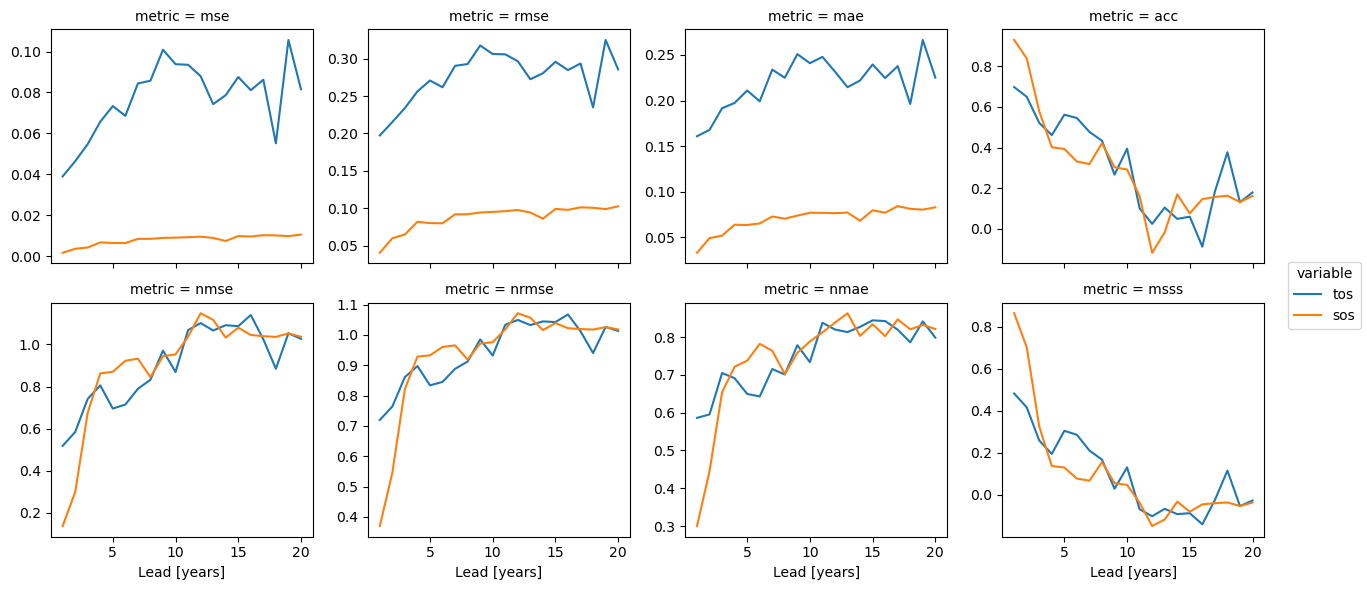

In [95]:
METRICS = ["mse", "rmse", "mae", "acc", "nmse", "nrmse", "nmae", "msss"]

result = []
for metric in METRICS:
    result.append(pm.verify(metric=metric, comparison="m2e", dim=["init", "member"]))

result = xr.concat(result, "metric")
result["metric"] = METRICS

# Leverage the `xarray` plotting wrapper to plot all results at once.
result.to_array().plot(
    col="metric", hue="variable", col_wrap=4, sharey=False, sharex=True
)

In [96]:
pm = pm.generate_uninitialized()
pm

<climpred.PerfectModelEnsemble>
Initialized:
    tos      (lead, init, member) float32 13.46 13.64 13.72 ... 13.55 13.57
    sos      (lead, init, member) float32 33.18 33.15 33.05 ... 33.18 33.26
Uninitialized:
    tos      (lead, init, member) float32 12.93 13.13 13.19 ... 13.73 13.39
    sos      (lead, init, member) float32 33.18 33.21 33.11 ... 33.14 33.17
Control:
    tos      (time) float32 13.5 13.74 13.78 13.86 ... 13.12 12.92 13.08 13.47
    sos      (time) float32 33.23 33.19 33.2 33.21 ... 33.15 33.22 33.16 33.18

In [97]:
pm = pm[["tos"]]

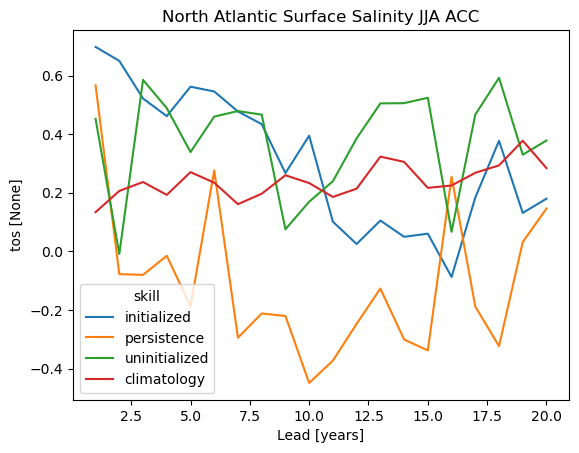

In [98]:
acc = pm.verify(
    metric="acc",
    comparison="m2e",
    dim=["init", "member"],
    reference=["persistence", "uninitialized", "climatology"],
)
acc.tos.plot(hue="skill")
plt.title("North Atlantic Surface Salinity JJA ACC")
plt.show()

# ESM4ppe

In [58]:
initialized = xr.Dataset()
control = xr.Dataset()
for variable in ['tos']:
    es = esm4ppe.esm4ppeObj(variable,'monthly').add_ensemble().add_control()
    initialized[variable] = es.ensemble[variable]
    control[variable] = es.control[variable]
initialized = initialized.sel(lead=slice(0,36))

Opening static... static opened.
Ensemble present in zarr store... opening... ensemble opened.
Control present in zarr store... opening...
control opened.


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


In [59]:
# hack to recast control time to first day of each month
import cftime
newtime = []
for i,time in enumerate(control['time']):
    newtime.append(cftime.DatetimeNoLeap(time.dt.year,time.dt.month,1))
control = control.assign_coords({'time':newtime})

In [60]:
pm = cp.PerfectModelEnsemble(initialized).add_control(control.chunk({'time':-1}))
pm

<climpred.PerfectModelEnsemble>
Initialized:
    tos      (member, init, lead, yh, xh) float32 dask.array<chunksize=(10, 40, 1, 576, 145), meta=np.ndarray>
Uninitialized:
    None
Control:
    tos      (time, yh, xh) float32 dask.array<chunksize=(3600, 576, 720), meta=np.ndarray>

In [61]:
pm = pm[["tos"]].sel(xh=-150,yh=0,method='nearest',drop=True)
with ProgressBar():
    pm = pm.compute()

[########################################] | 100% Completed | 4.24 sms
[########################################] | 100% Completed | 13.59 s


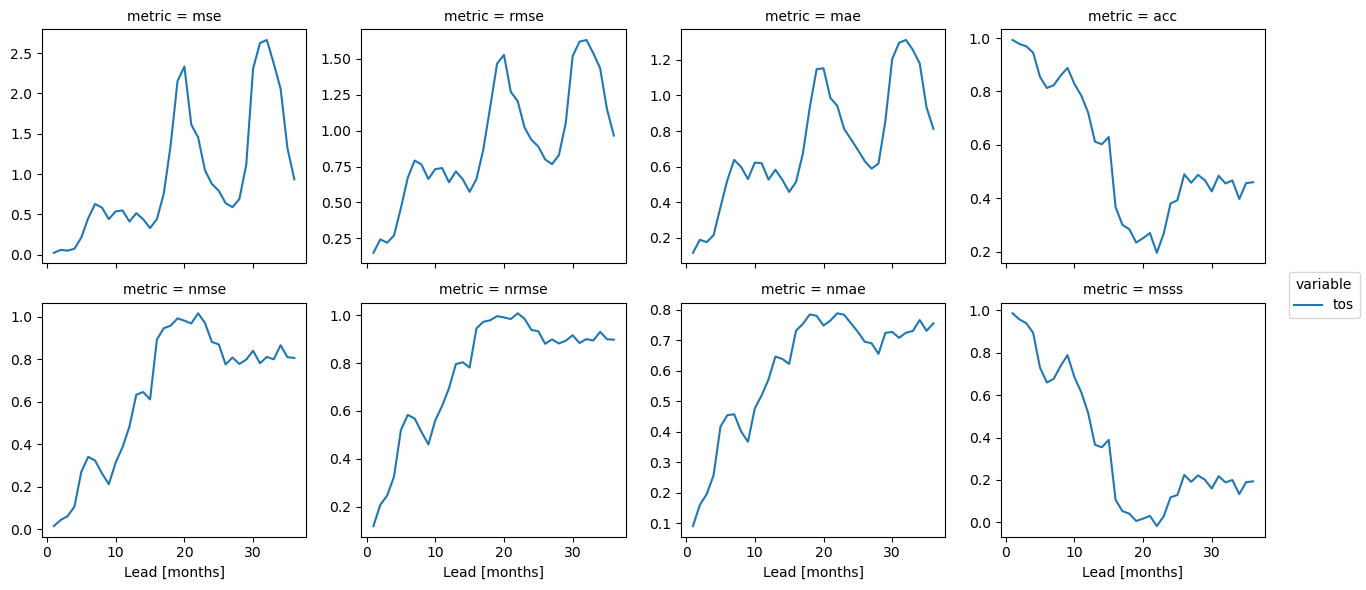

In [62]:
METRICS = ["mse", "rmse", "mae", "acc", "nmse", "nrmse", "nmae", "msss"]

result = []
for metric in METRICS:
    result.append(pm.verify(metric=metric, comparison="m2e", groupby='month',dim=["init", "member"]))

result = xr.concat(result, "metric")
result["metric"] = METRICS

# Leverage the `xarray` plotting wrapper to plot all results at once.
result.sel(month=4).to_array().plot(
    col="metric", hue="variable", col_wrap=4, sharey=False, sharex=True
)

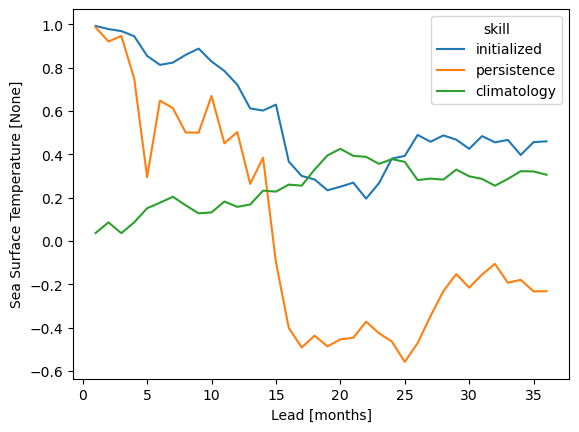

In [63]:
acc = pm.verify(
    metric="acc",
    comparison="m2e",
    dim=["init", "member"],
    groupby='month',
    reference=["persistence","climatology"],
)
acc.tos.sel(month=4).plot(hue="skill")
plt.title("")
plt.show()

In [81]:
s = cp.bootstrap.find_start_dates_for_given_init(control,initialized.init[-1])
s.time.sel(time='0399')

<xarray.DataArray 'time' (time: 1)>
array([cftime.DatetimeNoLeap(399, 10, 1, 0, 0, 0, 0, has_year_zero=True)],
      dtype=object)
Coordinates:
  * time     (time) object 0399-10-01 00:00:00

In [8]:
getattr(control.time.dt,'dayofyear').values == getattr(initialized.init[-1].dt,'dayofyear').values

array([False, False, False, ...,  True, False, False])

In [90]:
import cftime
import xarray as xr

ds = xr.Dataset(coords={'time':[cftime.DatetimeNoLeap(300,1,1),cftime.DatetimeNoLeap(301,1,1)]})
year_int = ds.time[0].dt.year.values
ds.sel(time=str(year_int).zfill(4))

<xarray.Dataset>
Dimensions:  (time: 1)
Coordinates:
  * time     (time) object 0300-01-01 00:00:00
Data variables:
    *empty*

In [86]:
ds

<xarray.Dataset>
Dimensions:  ()
Coordinates:
    time     object 0300-01-01 00:00:00
Data variables:
    *empty*

In [82]:
getattr(control.isel({'time': 0})['time'].dt,'day')

<xarray.DataArray 'day' ()>
array(1)
Coordinates:
    time     datetime64[ns] 1981-11-01

In [86]:
(getattr(control.isel({'time':0})['time'].dt,'month') == getattr(control['time'].dt,'month'))

<xarray.DataArray 'month' (time: 470)>
array([ True, False, False, False, False, False, False, False, False,
       False, False, False,  True, False, False, False, False, False,
       False, False, False, False, False, False,  True, False, False,
       False, False, False, False, False, False, False, False, False,
        True, False, False, False, False, False, False, False, False,
       False, False, False,  True, False, False, False, False, False,
       False, False, False, False, False, False,  True, False, False,
       False, False, False, False, False, False, False, False, False,
        True, False, False, False, False, False, False, False, False,
       False, False, False,  True, False, False, False, False, False,
       False, False, False, False, False, False,  True, False, False,
       False, False, False, False, False, False, False, False, False,
        True, False, False, False, False, False, False, False, False,
       False, False, False,  True, False, False, False, False, False,
       False, False, False, False, False, False,  True, False, False,
       False, False, False, False, False, False, False, False, False,
        True, False, False, False, False, False, False, False, False,
       False, False, False,  True, False, False, False, False, False,
       False, False, False, False, False, False,  True, False, False,
       False, False, False, False, False, False, False, False, False,
...
       False, False, False,  True, False, False, False, False, False,
       False, False, False, False, False, False,  True, False, False,
       False, False, False, False, False, False, False, False, False,
        True, False, False, False, False, False, False, False, False,
       False, False, False,  True, False, False, False, False, False,
       False, False, False, False, False, False,  True, False, False,
       False, False, False, False, False, False, False, False, False,
        True, False, False, False, False, False, False, False, False,
       False, False, False,  True, False, False, False, False, False,
       False, False, False, False, False, False,  True, False, False,
       False, False, False, False, False, False, False, False, False,
        True, False, False, False, False, False, False, False, False,
       False, False, False,  True, False, False, False, False, False,
       False, False, False, False, False, False,  True, False, False,
       False, False, False, False, False, False, False, False, False,
        True, False, False, False, False, False, False, False, False,
       False, False, False,  True, False, False, False, False, False,
       False, False, False, False, False, False,  True, False, False,
       False, False, False, False, False, False, False, False, False,
        True, False])
Coordinates:
  * time     (time) datetime64[ns] 1981-11-01 1981-12-01 ... 2020-12-01

In [87]:
getattr(control.isel({'time':0})['time'].dt,'month')

<xarray.DataArray 'month' ()>
array(11)
Coordinates:
    time     datetime64[ns] 1981-11-01

In [85]:
getattr(control['time'].dt,'month')

<xarray.DataArray 'month' (time: 470)>
array([11, 12,  1, ..., 10, 11, 12])
Coordinates:
  * time     (time) datetime64[ns] 1981-11-01 1981-12-01 ... 2020-12-01

In [65]:
cp.tutorial.load_dataset()

'MPI-control-1D': area averages for the MPI control run of SST/SSS.
'MPI-control-3D': lat/lon/time for the MPI control run of SST/SSS.
'MPI-PM-DP-1D': perfect model decadal prediction ensemble area averages of SST/SSS/AMO.
'MPI-PM-DP-3D': perfect model decadal prediction ensemble lat/lon/time of SST/SSS/AMO.
'CESM-DP-SST': hindcast decadal prediction ensemble of global mean SSTs.
'CESM-DP-SSS': hindcast decadal prediction ensemble of global mean SSS.
'CESM-DP-SST-3D': hindcast decadal prediction ensemble of eastern Pacific SSTs.
'CESM-LE': uninitialized ensemble of global mean SSTs.
'MPIESM_miklip_baseline1-hind-SST-global': hindcast initialized ensemble of global mean SSTs
'MPIESM_miklip_baseline1-hist-SST-global': uninitialized ensemble of global mean SSTs
'MPIESM_miklip_baseline1-assim-SST-global': assimilation in MPI-ESM of global mean SSTs
'ERSST': observations of global mean SSTs.
'FOSI-SST': reconstruction of global mean SSTs.
'FOSI-SSS': reconstruction of global mean SSS.
'FOSI

In [91]:
cp.show_versions()


INSTALLED VERSIONS
------------------
commit: None
python: 3.11.9 | packaged by conda-forge | (main, Apr 19 2024, 18:36:13) [GCC 12.3.0]
python-bits: 64
OS: Linux
OS-release: 4.18.0-553.5.1.el8_10.x86_64
machine: x86_64
processor: x86_64
byteorder: little
LC_ALL: None
LANG: en_US.UTF-8
LOCALE: en_US.UTF-8

climpred: 2.4.0
xarray: 2023.12.0
pandas: 2.2.2
numpy: 1.26.4
scipy: 1.13.1
cftime: 1.6.3
netcdf4: None
nc_time_axis: 1.4.1
matplotlib: 3.8.2
cf_xarray: 0.9.2
xclim: 0.50.0
dask: 2024.5.0
distributed: 2024.5.0
setuptools: 69.5.1
pip: 24.0
conda: None
IPython: 8.25.0
sphinx: None
